# C2 Tabular / ΔA Models — Results & Comparisons

Central plotting notebook for the tabular C2 classifiers (LR / RF / MLP) trained on
attribute vectors, C0 probability, embeddings and their counterfactual (ΔA) deltas.
Everything under sections 2–9 loads from `results/C2_custom_corrected/{disease}`
(currently: **effusion**). End-to-end CNN architectures live in **`ROC_cnn.ipynb`**.

| # | Section | Data source |
|---|---------|-------------|
| 1 | Setup — config, strategy registry, helpers | — |
| 2 | Data inventory — which runs exist | `cv_summary.csv` |
| 3 | ROC curves per model (single run) | `cv_detailed.json` |
| 4 | CF value ablation (B1 → B4 → M3) | `cv_detailed.json` |
| 5 | CF selection strategy comparison | `cv_summary.csv` |
| 6 | AUC vs CF count | `cv_summary.csv` |
| 7 | AUC heatmap — configs × strategy × CF count | `cv_summary.csv` |
| 8 | C0 confidence stratification | `cv_detailed.json` + fold predictions |
| 9 | Combining k CFs: avg-ΔA vs avg-scores vs stacking (k=3,16) | `cv_summary.csv` |
| 10 | Dual-CF isolation | `results/dual_cf_isolation` |
| 11 | Appendix: cross-architecture & dataset size | `results/C2_{custom,resnet50,vit}` |

Run **Setup** first; every other section is self-contained.
Section 5 reproduces `code/c2/c2_compare_selection_strategies.py`.

Each run directory looks like:
```
cv_results_<strategy>/cf_<k>/[distance_cosine/]
    cv_summary.csv            mean/std AUC per (model, config)
    cv_detailed.json          per-fold fpr/tpr/auc/y_prob/y_true (~90 MB)
    fold_<i>_predictions.csv  raw C0 prob + features per test sample
```

## 1. Setup — Imports, Config, Strategy Registry & Helpers

In [3]:
import json
import os
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score

sys.path.insert(0, '/zhome/d0/a/221493/thesis/code')
from plot_config import PLOT_COLORS, PLOT_LS, PLOT_LW

In [4]:
# ── Global config ─────────────────────────────────────────────────────────────
# RSNA Pneumonia variant of ROC_tabular.ipynb.
# RSNA DOES have C0 embeddings (1,024 emb_* columns in c2_data.csv), so every
# config is available. The pre-2026-07-23 runs are missing B3/B5 only because the
# pipeline's CONFIGS default omitted them at the time, not for want of features.
# Only the cf_ensemble / cf_ensemble_entropy strategies exist on disk
# (leak-corrected, StratifiedGroupKFold).
DISEASE     = 'rsna_pneumonia'
BASE_DIR    = '/zhome/d0/a/221493/thesis'
RESULTS_DIR = f'{BASE_DIR}/results/C2_custom_corrected/{DISEASE}'
OUTPUT_DIR  = 'images/'
os.makedirs(OUTPUT_DIR, exist_ok=True)

MODELS      = ['LR', 'RF', 'MLP']
MODEL_NAMES = {'LR': 'Logistic Regression', 'RF': 'Random Forest',
               'MLP': 'Multilayer Perceptron'}

# Config groups
# B1: prob only   B2: attrs only   B3: emb only   B4: prob+attrs   B5: prob+emb
# M1: ΔA only     M2: prob+ΔA      M3: prob+ΔA+attrs   M4: prob+ΔA+emb
# M5: prob+ΔA+attrs+emb            M6: prob+ΔA+attrs+CF-prob
# MCF1: prob+CF-prob               MCF2: prob+CF-prob+attrs+CF-attrs
# MCF3: MCF2+ΔA   MCF4: MCF3+emb+CF-emb   MCF5: MCF4+Δemb
#
# Full ladder. The loaders skip any config absent on disk and the heatmap drops
# all-NaN rows, so listing B3/B5 is harmless on runs that predate them.
BASELINE_CONFIGS = ['B1', 'B2', 'B3', 'B4', 'B5']           # no CF
DELTA_CONFIGS    = ['M1', 'M2', 'M3', 'M4', 'M5', 'M6']     # ΔA features
MCF_CONFIGS      = ['MCF1', 'MCF2', 'MCF3', 'MCF4', 'MCF5'] # raw CF features
CF_CONFIGS       = DELTA_CONFIGS + MCF_CONFIGS   # CF-dependent → differ across strategies
ALL_CONFIGS      = BASELINE_CONFIGS + CF_CONFIGS

LABELS = {
    'B1': 'B1 (Prob only)',        'B2': 'B2 (Attrs only)',
    'B3': 'B3 (Embeddings only)',  'B4': 'B4 (Prob+Attrs)',
    'B5': 'B5 (Prob+Emb)',         'M1': 'M1 (ΔA only)',
    'M2': 'M2 (Prob+ΔA)',          'M3': 'M3 (Prob+ΔA+Attrs)',
    'M4': 'M4 (Prob+ΔA+Emb)',      'M5': 'M5 (Prob+ΔA+Attrs+Emb)',
    'M6': 'M6 (Prob+ΔA+Attrs+CF)',
    'MCF1': 'MCF1 (Prob+CF-Prob)',
    'MCF2': 'MCF2 (Prob+CF-Prob+Attrs+CF-Attrs)',
    'MCF3': 'MCF3 (MCF2+ΔA)',
    'MCF4': 'MCF4 (MCF3+Emb+CF-Emb)',
    'MCF5': 'MCF5 (MCF4+ΔEmb)',
}

COLORS, LINESTYLES, LINEWIDTHS = PLOT_COLORS, PLOT_LS, PLOT_LW


In [5]:
# ── CF selection strategy / run-variant registry ──────────────────────────────
# key → (subdir under RESULTS_DIR, distance metric, plot label)
# Non-L1 runs live in a distance_<metric>/ subdir inside the cf_<k> directory.
# A '{cf}' placeholder means the run is nested inside another run's cf dir
# (feature-set variants: entropy replaces C0 prob / prob removed entirely).
STRATEGIES = {
    'correct_cf':          ('cv_results_correct_cf',          'l1',     'Correct CF (L1)'),
    'correct_cf_cosine':   ('cv_results_correct_cf',          'cosine', 'Correct CF (Cosine)'),
    'entropy':             ('cv_results_correct_cf/cf_{cf}/TEST_entropy',     'l1',
                            'Correct CF (Entropy for Prob)'),
    'no_prob':             ('cv_results_correct_cf/cf_{cf}/TEST_removedprob', 'l1',
                            'Correct CF (No Prob)'),
    
    # BIG MLP COMBINES ENSEMBLE AND ENTROPY
    # ⚠ LEAK-CORRECTED RUNS: folds are patient-grouped (StratifiedGroupKFold on
    # patient_id; zero overlap confirmed in job logs). On RSNA the grouping is a
    # no-op — one image per study — but the runs below are the post-fix ones.
    # All OTHER strategies in this dict predate the fix and may be inflated by
    # same-patient train/test leakage.
    #
    # ENTROPY SEMANTICS — the two keys below are NOT interchangeable:
    #   cf_ensemble_entropy          H(p) is ADDED to the M/MCF configs; the B*
    #                                baselines keep raw prob and are untouched.
    #                                Jobs 28939982/28939983, 2026-07-23.
    #   cf_ensemble_entropy_swapped  the 2026-07-17 runs, where H(p) REPLACED
    #                                prob everywhere — including B1, which is
    #                                prob-only and so was silently handed a
    #                                nonlinear confidence basis (LR B1 0.73 vs
    #                                0.52 on raw prob). Baseline-vs-ΔA gaps from
    #                                these are not comparable to effusion /
    #                                pneumothorax. Kept only for the comparison.
    'cf_ensemble_entropy': ('cv_results_cf_ensemble/cf_{cf}/distance_l1/'
                            'strategy_correct_cf/TEST_entropy_added(M-only)', 'l1',
                            'CF Ensemble + Entropy (avg k scores)'),
    'cf_ensemble_entropy_swapped': ('cv_results_cf_ensemble/cf_{cf}/TEST_entropy', 'l1',
                            'CF Ensemble + Entropy (swapped prob, superseded)'),
    'correct_cf_emb':      ('cv_results_correct_cf_emb',      'l1',     'Correct CF (Emb. Space)'),
    'extended_correct_cf': ('cv_results_extended_correct_cf', 'l1',     'Correct CF (Extra Texture)'),
    'unmatched':           ('cv_results_unmatched',           'l1',     'Opposite Pred (L1)'),
    'unmatched_cosine':    ('cv_results_unmatched',           'cosine', 'Unmatched (Cosine)'),
    'gt_routing':          ('cv_results_gt_routing',          'l1',     'GT Routing (L1)'),
    'gt_routing_cosine':   ('cv_results_gt_routing',          'cosine', 'GT Routing (Cosine, oracle)'),
    'cf_ensemble':         ('cv_results_cf_ensemble',         'l1',     'CF Ensemble (avg k scores)'),
    'cf_stack':            ('cv_results_cf_stack',            'l1',     'CF Stack (meta-LR on k logits)'),
    'train_only':          ('cv_results',                     'l1',     'Matched (L1, Train Only)'),
}

STRATEGY_COLORS = {
    'correct_cf':          '#0072B2',   # blue          ── correct_cf pair
    'correct_cf_cosine':   '#56B4E9',   # sky blue      ──┘ (lighter sibling)
    'entropy':             '#D55E00',   # vermillion
    'no_prob':             '#009E73',   # green
    'correct_cf_emb':      '#CC79A7',   # pink
    'extended_correct_cf': '#9467BD',   # purple
    'unmatched':           '#E69F00',   # orange
    'unmatched_cosine':    '#F0E442',   # yellow        ──┘ (lighter sibling of orange)
    'gt_routing':          '#000000',   # black (oracle)
    'gt_routing_cosine':   '#7F7F7F',   # grey  (oracle sibling)
    'cf_ensemble':         '#5C3317',   # dark chocolate
    'cf_stack':            '#D2A679',   # light tan
    'train_only':          '#66A61E',   # olive
    'cf_ensemble_entropy': '#E41A1C',   # red (BIG MLP, combines ensemble and entropy)
    'cf_ensemble_entropy_swapped': '#9E9E9E',  # grey (superseded swapped-prob run)
    'cf_ensemble_balanced': '#17BECF',  # teal (ensemble on balanced dataset)
}


STRATEGY_MARKERS = {
    'correct_cf': 'o', 'correct_cf_cosine': 'v', 'entropy': '<', 'no_prob': '>',
    'correct_cf_emb': '^', 'extended_correct_cf': 'D', 'unmatched': 's',
    'unmatched_cosine': 'P', 'gt_routing': '*', 'gt_routing_cosine': 'X',
    'cf_ensemble': 'h', 'cf_stack': 'p', 'train_only': 'd',
    'cf_ensemble_entropy': 'X',
    'cf_ensemble_entropy_swapped': 'x',
    'cf_ensemble_balanced': 'H',
}

CF_COUNTS = [1, 3, 5, 16, 30]   # CF counts a run may exist for


In [6]:
# ── Plot style ────────────────────────────────────────────────────────────────
plt.style.use('seaborn-v0_8-white')
plt.rcParams.update({
    'font.family': 'sans-serif', 'font.size': 13,
    'axes.titlesize': 13, 'axes.labelsize': 13,
    'xtick.labelsize': 12, 'ytick.labelsize': 12,
    'legend.fontsize': 11,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.linewidth': 1.2, 'grid.alpha': 0.3,
    'grid.linewidth': 0.6, 'lines.linewidth': 1.8,
})

In [7]:
# ── Loading helpers ───────────────────────────────────────────────────────────
def run_dir(strategy, cf_count):
    """Directory of one (strategy, cf_count) run."""
    subdir, distance, _ = STRATEGIES[strategy]
    if '{cf}' in subdir:   # nested variant (e.g. TEST_entropy inside correct_cf)
        d = os.path.join(RESULTS_DIR, subdir.format(cf=cf_count))
    else:
        d = os.path.join(RESULTS_DIR, subdir, f'cf_{cf_count}')
    return d if distance == 'l1' else os.path.join(d, f'distance_{distance}')

def has_run(strategy, cf_count):
    return os.path.exists(os.path.join(run_dir(strategy, cf_count), 'cv_summary.csv'))

def load_summary(strategy, cf_count):
    """cv_summary.csv → tidy df filtered to MODELS × ALL_CONFIGS (None if missing)."""
    path = os.path.join(run_dir(strategy, cf_count), 'cv_summary.csv')
    if not os.path.exists(path):
        return None
    df = pd.read_csv(path)
    df = df[df['model'].isin(MODELS) & df['config'].isin(ALL_CONFIGS)].copy()
    df.insert(0, 'strategy', strategy)
    df.insert(1, 'cf_count', cf_count)
    return df

_detailed_cache = {}
def load_detailed(strategy, cf_count):
    """cv_detailed.json → {model: {config: [fold dicts]}}. ~90 MB each → cached."""
    key = (strategy, cf_count)
    if key not in _detailed_cache:
        with open(os.path.join(run_dir(strategy, cf_count), 'cv_detailed.json')) as f:
            _detailed_cache[key] = json.load(f)
    return _detailed_cache[key]

common_fpr = np.linspace(0, 1, 300)

def mean_roc(folds):
    """Fold-averaged ROC curve and AUC from a list of fold dicts."""
    tprs = [np.interp(common_fpr, f['fpr'], f['tpr']) for f in folds]
    aucs = [f['auc'] for f in folds]
    return {'fpr': common_fpr, 'tpr': np.mean(tprs, axis=0), 'std': np.std(tprs, axis=0),
            'auc': np.mean(aucs), 'auc_std': np.std(aucs)}

def add_b1_line(ax, b1_auc, label='B1 (Prob only)'):
    """Thin light-grey dashed B1 reference — shown in every config-comparison plot."""
    ax.axhline(b1_auc, color=COLORS['B1'], linestyle=LINESTYLES['B1'],
               lw=LINEWIDTHS['B1'], label=f'{label} = {b1_auc:.3f}', zorder=1)

## 2. Data Inventory

Which (strategy × CF count) runs exist for the current disease — ✓ means a
`cv_summary.csv` is present. Anything not in the registry is listed below the table.

Notes:
- *Entropy for Prob* and *No Prob* are feature-set variants nested inside
  `cv_results_correct_cf/cf_<k>/TEST_entropy` / `TEST_removedprob` (M/MCF configs only,
  no B baselines). The lowercase `test_entropy` dir at cf_1 is an older superseded run.
- *CF Ensemble* trains on the nearest CF and averages the k test-time scores
  (`c2_cv_pipeline_cf_ensemble.py`).
- **Patient-leak fix (2026-07-16):** the *CF Ensemble + Entropy* runs are the
  **only** ones generated after the CV pipelines switched to
  `StratifiedGroupKFold` on `patient_id` (before, images from the same patient
  could sit in both train and test folds). On RSNA this is a no-op — `patient_id`
  is the StudyInstanceUID and RSNA is one image per study — but every other run
  dir predates the fix, so do not compare those AUCs against the fixed runs.
- **Entropy fix (2026-07-23):** the current runs live at
  `cv_results_cf_ensemble/cf_<k>/distance_l1/strategy_correct_cf/TEST_entropy_added(M-only)`
  (jobs 28939982 / 28939983) and add H(p) to the M/MCF configs only, leaving the
  B* baselines on raw prob. The older flat `cf_<k>/TEST_entropy` dirs
  (`cf_ensemble_entropy_swapped`) swapped H(p) in **everywhere**, which inflated
  B1 from ~0.52 to ~0.73 for LR and understated the baseline-vs-ΔA gap. The
  margin / `prob_*` exclusion (`c2_feature_spec.py`) is present in both.


In [8]:
inventory = pd.DataFrame(
    {f'CF={cf}': {STRATEGIES[s][2]: '✓' if has_run(s, cf) else '—' for s in STRATEGIES}
     for cf in CF_COUNTS}
)
print(f'Available runs — {DISEASE}  ({RESULTS_DIR})')
display(inventory)

# Result subdirs not covered by the registry (incomplete or experimental runs)
known = {subdir for subdir, _, _ in STRATEGIES.values()}
extra = sorted(d for d in os.listdir(RESULTS_DIR)
               if d.startswith('cv_results') and d not in known)
if extra:
    print('Not in registry (incomplete/experimental):', ', '.join(extra))

Available runs — rsna_pneumonia  (/zhome/d0/a/221493/thesis/results/C2_custom_corrected/rsna_pneumonia)


,CF=1,CF=3,CF=5,CF=16,CF=30
Correct CF (L1),—,—,—,—,—
Correct CF (Cosine),—,—,—,—,—
Correct CF (Entropy for Prob),—,—,—,—,—
Correct CF (No Prob),—,—,—,—,—
CF Ensemble + Entropy (avg k scores),—,—,—,—,—
"CF Ensemble + Entropy (swapped prob, superseded)",✓,—,—,✓,—
Correct CF (Emb. Space),—,—,—,—,—
Correct CF (Extra Texture),—,—,—,—,—
Opposite Pred (L1),—,—,—,—,—
Unmatched (Cosine),—,—,—,—,—


## 3. ROC Curves — per Model (single run)

Fold-averaged ROC curves for one chosen (strategy, CF count) run:
one figure per model with baselines + ΔA configs (left) and CF-enriched MCF configs (right).

In [9]:
# ── Which run to plot ─────────────────────────────────────────────────────────
# RSNA runs on disk: cf_ensemble (cf_3) and cf_ensemble_entropy (cf_1, cf_16).
ROC_STRATEGY = 'cf_ensemble_entropy'   # 'cf_ensemble' (cf_3) | 'cf_ensemble_entropy' (cf_1/cf_16)
ROC_CF_COUNT = 16

detailed = load_detailed(ROC_STRATEGY, ROC_CF_COUNT)
run_tag  = f'{STRATEGIES[ROC_STRATEGY][2]} | CF={ROC_CF_COUNT}'
print(f'Loaded {run_tag}  →  models: {[m for m in detailed if m in MODELS]}')


FileNotFoundError: [Errno 2] No such file or directory: '/zhome/d0/a/221493/thesis/results/C2_custom_corrected/rsna_pneumonia/cv_results_cf_ensemble/cf_16/distance_l1/strategy_correct_cf/TEST_entropy_added(M-only)/cv_detailed.json'

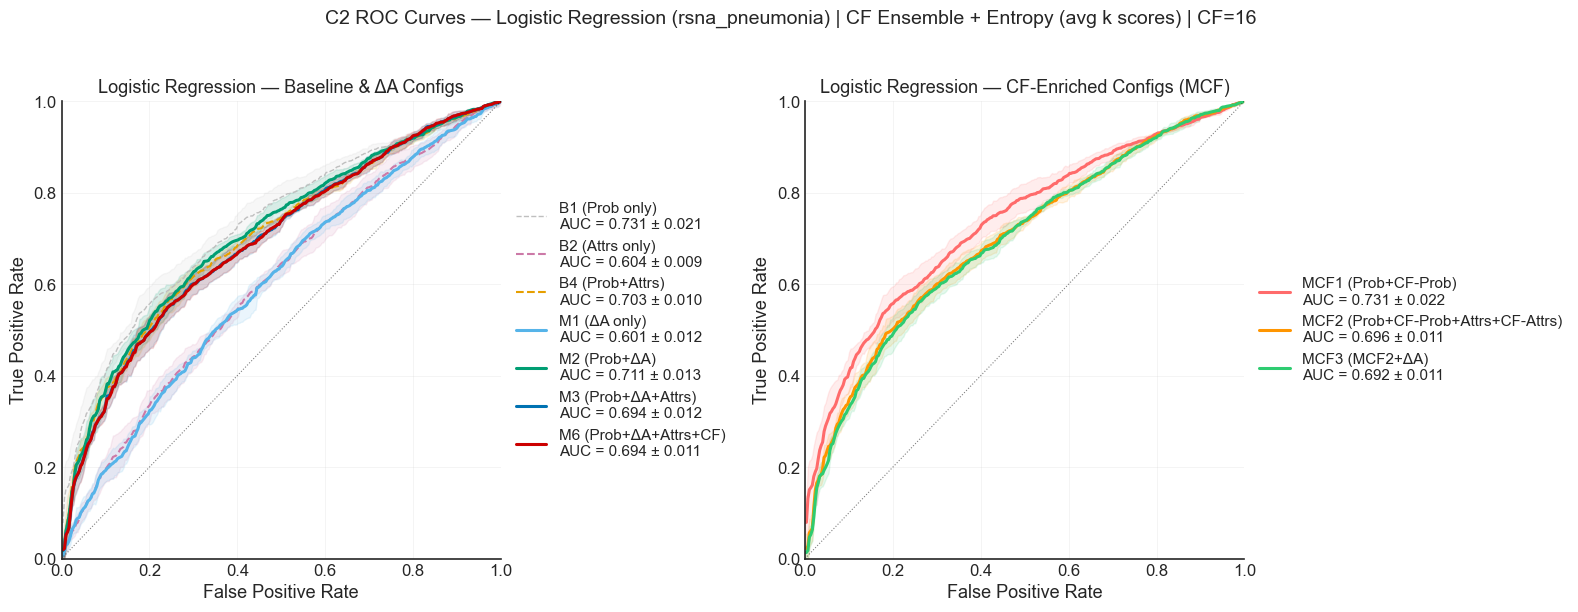

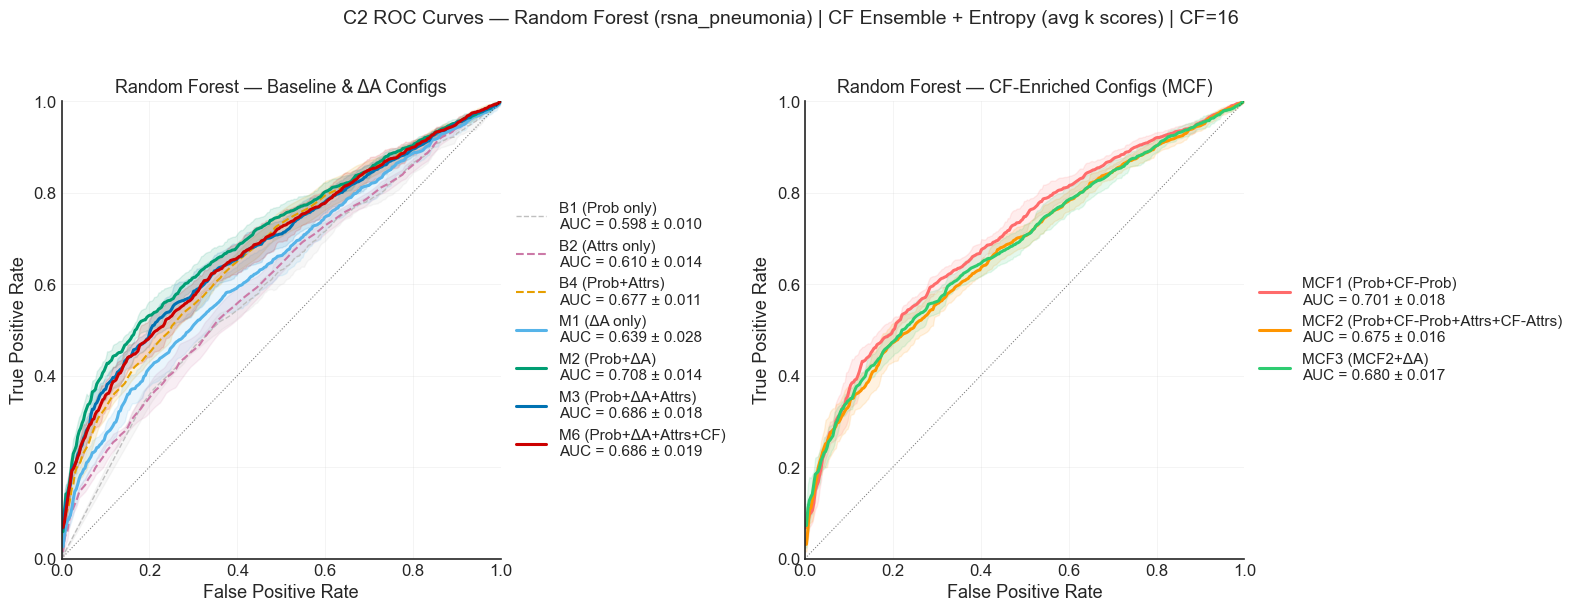

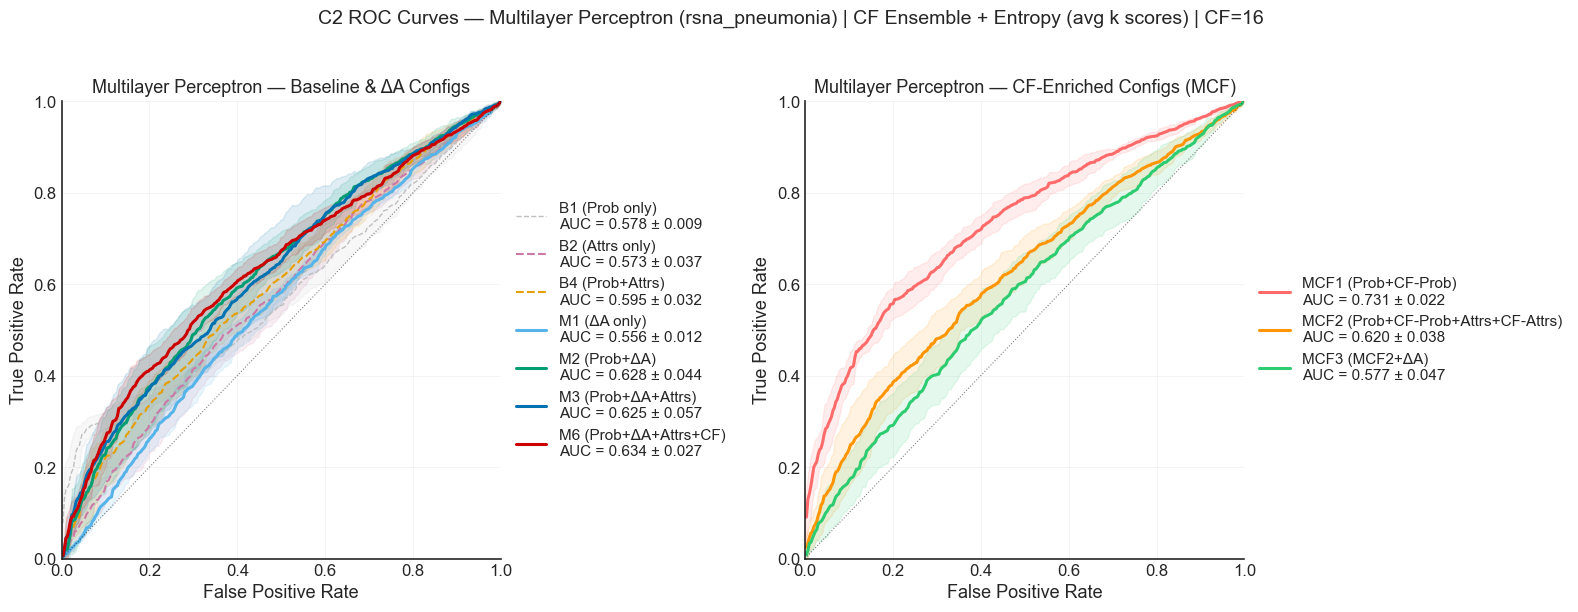

In [ ]:
def plot_roc_panel(ax, model, configs, title):
    for config in configs:
        if config not in detailed[model]:
            continue
        d = mean_roc(detailed[model][config])
        ax.plot(d['fpr'], d['tpr'], color=COLORS[config],
                lw=LINEWIDTHS[config], ls=LINESTYLES[config],
                label=f"{LABELS[config]}\nAUC = {d['auc']:.3f} ± {d['auc_std']:.3f}")
        ax.fill_between(d['fpr'], d['tpr'] - d['std'], d['tpr'] + d['std'],
                        color=COLORS[config], alpha=0.12)
    ax.plot([0, 1], [0, 1], 'k:', lw=0.8, alpha=0.5)
    ax.set_xlabel('False Positive Rate'); ax.set_ylabel('True Positive Rate')
    ax.set_title(title, size=13)
    ax.set_xlim(0, 1); ax.set_ylim(0, 1)
    ax.legend(loc='center left', bbox_to_anchor=(1.02, 0.5), borderaxespad=0)
    ax.grid(alpha=0.30, linewidth=0.5)

for model in MODELS:
    fig, (ax_bm, ax_mcf) = plt.subplots(1, 2, figsize=(16, 6))
    plot_roc_panel(ax_bm, model, BASELINE_CONFIGS + DELTA_CONFIGS,
                   f'{MODEL_NAMES[model]} — Baseline & ΔA Configs')
    plot_roc_panel(ax_mcf, model, MCF_CONFIGS,
                   f'{MODEL_NAMES[model]} — CF-Enriched Configs (MCF)')
    fig.suptitle(f'C2 ROC Curves — {MODEL_NAMES[model]} ({DISEASE}) | {run_tag}',
                 size=14, y=1.02)
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR,
                f'roc_{model.lower()}_{ROC_STRATEGY}_cf{ROC_CF_COUNT}.png'),
                dpi=150, bbox_inches='tight')
    plt.show()

In [ ]:
# ── AUC summary table for this run ────────────────────────────────────────────
summ = load_summary(ROC_STRATEGY, ROC_CF_COUNT)
tbl = summ.assign(auc=summ['mean_auc'].map('{:.3f}'.format) + ' ± '
                       + summ['std_auc'].map('{:.3f}'.format))
tbl = tbl.pivot(index='config', columns='model', values='auc').reindex(ALL_CONFIGS)[MODELS]
tbl.insert(0, 'Description', [LABELS[c] for c in tbl.index])
print(f'AUC (5-fold CV) — {DISEASE} | {run_tag}')
display(tbl)

AUC (5-fold CV) — rsna_pneumonia | CF Ensemble + Entropy (avg k scores) | CF=16


model,Description,LR,RF,MLP
config,,,,
B1,B1 (Prob only),0.731 ± 0.021,0.598 ± 0.010,0.578 ± 0.009
B2,B2 (Attrs only),0.604 ± 0.009,0.610 ± 0.014,0.573 ± 0.037
B4,B4 (Prob+Attrs),0.703 ± 0.010,0.677 ± 0.011,0.595 ± 0.032
M1,M1 (ΔA only),0.601 ± 0.012,0.639 ± 0.028,0.556 ± 0.012
M2,M2 (Prob+ΔA),0.711 ± 0.013,0.708 ± 0.014,0.628 ± 0.044
M3,M3 (Prob+ΔA+Attrs),0.694 ± 0.012,0.686 ± 0.018,0.625 ± 0.057
M6,M6 (Prob+ΔA+Attrs+CF),0.694 ± 0.011,0.686 ± 0.019,0.634 ± 0.027
MCF1,MCF1 (Prob+CF-Prob),0.731 ± 0.022,0.701 ± 0.018,0.731 ± 0.022
MCF2,MCF2 (Prob+CF-Prob+Attrs+CF-Attrs),0.696 ± 0.011,0.675 ± 0.016,0.620 ± 0.038


## 5. CF Selection Strategy Comparison

How the counterfactual neighbour is *chosen*, at a fixed CF count
(ported from `code/c2/c2_compare_selection_strategies.py`), plus the run variants:
entropy-for-prob, no-prob (both cf_1 only) and the CF score ensemble.
Only CF-dependent configs (M\*, MCF\*) differ across strategies; B\* baselines are
shown as reference lines — best baseline (black) and B1 (thin light-grey).

In [ ]:
COMPARE_CF_COUNT = 16   # cf_ensemble_entropy exists at cf_1 and cf_16

# ── Which strategies to plot ──────────────────────────────────────────────────
# RSNA only has cf_ensemble (cf_3) and cf_ensemble_entropy (cf_1/cf_16) on disk;
# other strategies are auto-skipped with a warning.
SELECTED_STRATEGIES = [
    'cf_ensemble_entropy',
    'cf_ensemble']

COMPARE_STRATEGIES = ([s for s in STRATEGIES if s != 'train_only']
                      if SELECTED_STRATEGIES is None else SELECTED_STRATEGIES)


frames  = {s: load_summary(s, COMPARE_CF_COUNT) for s in COMPARE_STRATEGIES}
missing = [s for s, f in frames.items() if f is None]
if missing:
    print('⚠ No run found (skipped):', ', '.join(missing))
long_df = pd.concat([f for f in frames.values() if f is not None], ignore_index=True)

long_df.to_csv(os.path.join(OUTPUT_DIR,
               f'strategy_comparison_cf{COMPARE_CF_COUNT}_{DISEASE}.csv'), index=False)
print(f"{long_df['strategy'].nunique()} strategies loaded (CF={COMPARE_CF_COUNT}, {DISEASE})")


⚠ No run found (skipped): cf_ensemble
1 strategies loaded (CF=16, rsna_pneumonia)


In [11]:
# ── Per-model comparison: x = CF-dependent config, one line per strategy ──────
def plot_strategy_comparison(long_df, model):
    sub = long_df[long_df['model'] == model]
    if sub.empty:
        print(f'⚠ No data for {model}')
        return
    
    
    # best baseline across ALL model families, not just this one
    base = long_df[long_df['config'].isin(BASELINE_CONFIGS)]
    best = base.loc[base['mean_auc'].idxmax()]
    
    fig, ax = plt.subplots(figsize=(6, 6))
    for strategy in COMPARE_STRATEGIES:
        strat_df = sub[sub['strategy'] == strategy]
        present  = [c for c in CF_CONFIGS if c in strat_df['config'].values]
        if not present:
            continue
        strat_df = strat_df.set_index('config').loc[present]
        x    = [CF_CONFIGS.index(c) for c in present]
        y    = strat_df['mean_auc'].values
        yerr = strat_df['std_auc'].values
        ax.plot(x, y, color=STRATEGY_COLORS[strategy], lw=2.4, marker='o',
                markersize=7, label=STRATEGIES[strategy][2])
        ax.fill_between(x, y - yerr, y + yerr, color=STRATEGY_COLORS[strategy], alpha=0.15)

    # No-CF baselines (identical across strategies): best B* + the B1 reference
    if not base.empty:
        ax.axhline(best['mean_auc'], color='black', linestyle='--', lw=1.6,
                   label=f"Best baseline ({best['model']} {best['config']}) = {best['mean_auc']:.3f}")

    # annotate the single highest-AUC point across all plotted strategies
    plotted = sub[sub['strategy'].isin(COMPARE_STRATEGIES)
                  & sub['config'].isin(CF_CONFIGS)]
    if not plotted.empty:
        top = plotted.loc[plotted['mean_auc'].idxmax()]
        xt = CF_CONFIGS.index(top['config'])
        yt = top['mean_auc']
        ax.annotate(
            f"{STRATEGIES[top['strategy']][2]} {top['config']}\nAUC = {yt:.3f}",
            xy=(xt, yt), xytext=(0, 28), textcoords='offset points',
            ha='center', va='bottom', fontsize=10,
            bbox=dict(boxstyle='round,pad=0.3', fc='white', ec='#333333', lw=0.8),
            arrowprops=dict(arrowstyle='->', color='#333333', lw=1.0))
        ax.scatter([xt], [yt], s=90, facecolors='none',
                   edgecolors='#333333', linewidths=1.6, zorder=5)

    ax.set_xticks(range(len(CF_CONFIGS)))
    ax.set_xticklabels(CF_CONFIGS, rotation=45, ha='right')
    ax.set_ylim(0.75, 0.86)
    ax.set_xlabel('Config'); ax.set_ylabel('Mean AUROC (5-fold CV)')
    ax.set_title(f'CF Selection Strategies — {DISEASE.capitalize()} '
                 f'{model} (CF={COMPARE_CF_COUNT})')
    ax.legend(loc='lower left', framealpha=0.9, edgecolor='#cccccc', fontsize=11)
    ax.grid(alpha=0.3, linewidth=0.5)
    plt.ylim(0.75, 0.86)
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR,
                f'strategy_comparison_{model}_cf{COMPARE_CF_COUNT}_{DISEASE}.png'),
                dpi=300, bbox_inches='tight')
    plt.show()

for model in MODELS:
    plot_strategy_comparison(long_df, model)

NameError: name 'long_df' is not defined

In [ ]:
# ── Leaderboards: strategy × config, one per model ────────────────────────────
for model in MODELS:
    sub = long_df[(long_df['model'] == model) & long_df['config'].isin(CF_CONFIGS)]
    if sub.empty:
        continue
    pivot = (sub.pivot(index='strategy', columns='config', values='mean_auc')
                .reindex(index=[s for s in COMPARE_STRATEGIES
                                if s in sub['strategy'].values],
                         columns=[c for c in CF_CONFIGS if c in sub['config'].values]))
    print(f'Leaderboard — {model} (mean AUC, 5-fold CV, CF={COMPARE_CF_COUNT})')
    display(pivot.round(4))

# Top 5 overall — CF-dependent configs only
top5 = (long_df[long_df['config'].isin(CF_CONFIGS)]
        .sort_values('mean_auc', ascending=False).head(5))
print('Top 5 overall (CF-dependent configs):')
display(top5[['strategy', 'model', 'config', 'mean_auc', 'std_auc']].round(4))

# print whole table for reference (uncomment if needed)
print('All results (CF-dependent configs):')
print(long_df[long_df['config'].isin(CF_CONFIGS)]
      .sort_values(['model', 'config', 'strategy']) )

# save full table
long_df.to_csv(os.path.join(OUTPUT_DIR,
               f'strategy_comparison_cf{COMPARE_CF_COUNT}_{DISEASE}.csv'), index=False)

Leaderboard — LR (mean AUC, 5-fold CV, CF=16)


config,M1,M2,M3,M6,MCF1,MCF2,MCF3
strategy,,,,,,,
cf_ensemble_entropy,0.6009,0.7107,0.6945,0.6941,0.7312,0.6965,0.6923


Leaderboard — RF (mean AUC, 5-fold CV, CF=16)


config,M1,M2,M3,M6,MCF1,MCF2,MCF3
strategy,,,,,,,
cf_ensemble_entropy,0.6388,0.7083,0.6863,0.6858,0.7012,0.6752,0.6796


Leaderboard — MLP (mean AUC, 5-fold CV, CF=16)


config,M1,M2,M3,M6,MCF1,MCF2,MCF3
strategy,,,,,,,
cf_ensemble_entropy,0.5556,0.628,0.6249,0.6343,0.731,0.6196,0.5769


Top 5 overall (CF-dependent configs):


,strategy,model,config,mean_auc,std_auc
7,cf_ensemble_entropy,LR,MCF1,0.7312,0.0217
27,cf_ensemble_entropy,MLP,MCF1,0.7310,0.0217
4,cf_ensemble_entropy,LR,M2,0.7107,0.0128
14,cf_ensemble_entropy,RF,M2,0.7083,0.0136
17,cf_ensemble_entropy,RF,MCF1,0.7012,0.0184


All results (CF-dependent configs):
               strategy  cf_count model config  mean_auc   std_auc   min_auc  \
3   cf_ensemble_entropy        16    LR     M1  0.600901  0.012017  0.581650   
4   cf_ensemble_entropy        16    LR     M2  0.710696  0.012808  0.690462   
5   cf_ensemble_entropy        16    LR     M3  0.694476  0.012098  0.681697   
6   cf_ensemble_entropy        16    LR     M6  0.694100  0.011356  0.681877   
7   cf_ensemble_entropy        16    LR   MCF1  0.731226  0.021670  0.702227   
8   cf_ensemble_entropy        16    LR   MCF2  0.696487  0.010923  0.683575   
9   cf_ensemble_entropy        16    LR   MCF3  0.692326  0.011476  0.679888   
23  cf_ensemble_entropy        16   MLP     M1  0.555649  0.012427  0.532267   
24  cf_ensemble_entropy        16   MLP     M2  0.628041  0.044385  0.590640   
25  cf_ensemble_entropy        16   MLP     M3  0.624946  0.057342  0.514759   
26  cf_ensemble_entropy        16   MLP     M6  0.634304  0.027209  0.595791   
27  

## 6. AUC vs CF Count

Effect of the number of counterfactuals for a fixed (model, config),
one line per strategy across all its available CF counts.
B1 uses no CFs → flat light-grey reference line.

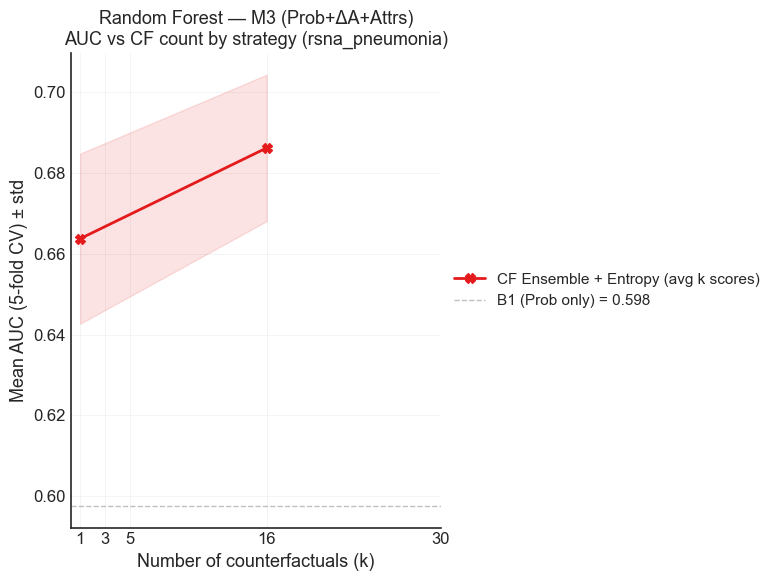

,CF=1,CF=16
CF Ensemble + Entropy (avg k scores),0.6638,0.6863


In [ ]:
FOCUS_MODEL  = 'RF'
FOCUS_CONFIG = 'M3'

fig, ax = plt.subplots(figsize=(8, 6))
b1_auc, table_rows = None, {}
for strategy in STRATEGIES:
    pts = []
    for cf in CF_COUNTS:
        df = load_summary(strategy, cf)
        if df is None:
            continue
        row = df[(df['model'] == FOCUS_MODEL) & (df['config'] == FOCUS_CONFIG)]
        if row.empty:
            continue
        pts.append((cf, row['mean_auc'].iloc[0], row['std_auc'].iloc[0]))
        if b1_auc is None:
            b1 = df[(df['model'] == FOCUS_MODEL) & (df['config'] == 'B1')]
            if not b1.empty:
                b1_auc = b1['mean_auc'].iloc[0]
    if not pts:
        continue
    cfs, means, stds = map(np.array, zip(*pts))
    ax.plot(cfs, means, color=STRATEGY_COLORS[strategy],
            marker=STRATEGY_MARKERS[strategy], lw=2, ms=7,
            label=STRATEGIES[strategy][2])
    ax.fill_between(cfs, means - stds, means + stds,
                    color=STRATEGY_COLORS[strategy], alpha=0.12)
    table_rows[STRATEGIES[strategy][2]] = {f'CF={c}': m for c, m, _ in pts}

if b1_auc is not None:
    add_b1_line(ax, b1_auc)

ax.set_xticks(CF_COUNTS); ax.set_xticklabels([str(c) for c in CF_COUNTS])
ax.set_xlabel('Number of counterfactuals (k)')
ax.set_ylabel('Mean AUC (5-fold CV) ± std')
ax.set_title(f'{MODEL_NAMES[FOCUS_MODEL]} — {LABELS[FOCUS_CONFIG]}\n'
             f'AUC vs CF count by strategy ({DISEASE})')
ax.legend(loc='center left', bbox_to_anchor=(1.02, 0.5), borderaxespad=0)
ax.grid(alpha=0.3, linewidth=0.5)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR,
            f'auc_vs_cf_count_{FOCUS_MODEL}_{FOCUS_CONFIG}_{DISEASE}.png'),
            dpi=300, bbox_inches='tight')
plt.show()

display(pd.DataFrame(table_rows).T.round(4))

## 7. AUC Heatmap — Configs × (Strategy × CF count)

Full overview per model, built from the `cv_summary.csv` files.
Black boxes mark the best config within each column; white lines separate
the B / M / MCF config groups (rows) and the strategy blocks (columns).

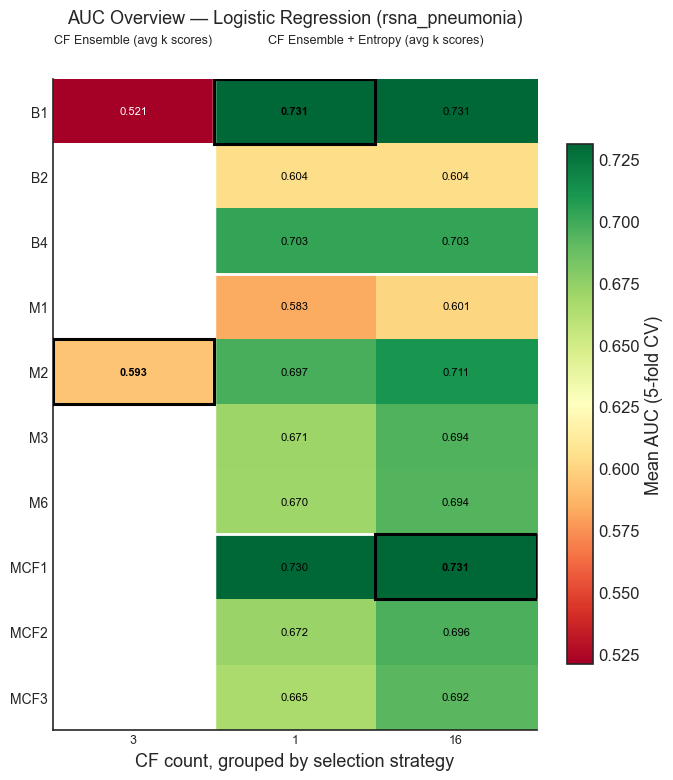

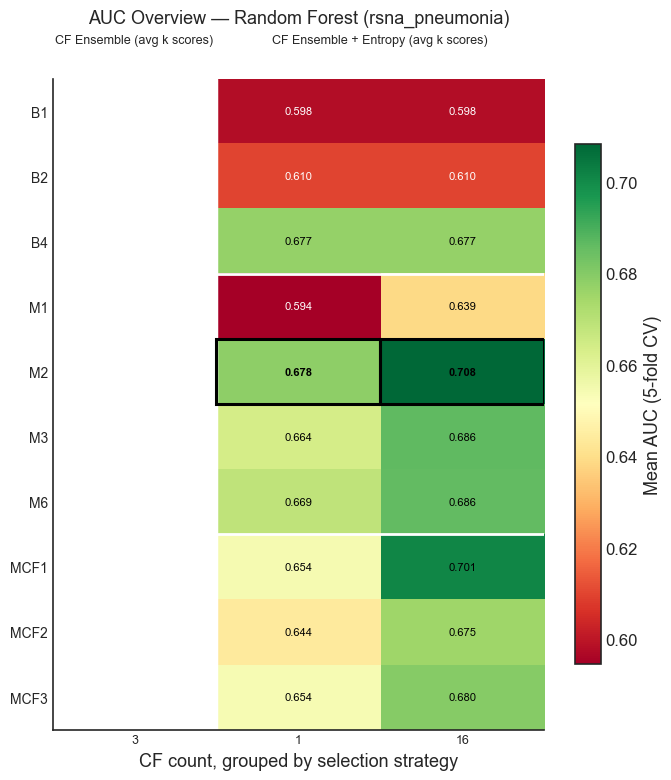

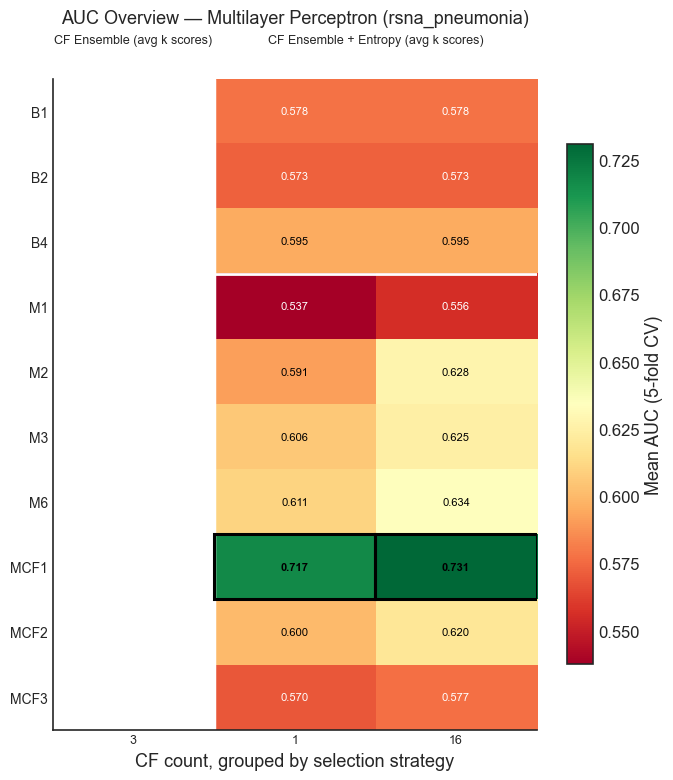

In [ ]:
HEATMAP_STRATEGIES = ['cf_ensemble', 'cf_ensemble_entropy']   # only these exist for RSNA

for model in MODELS:
    cols, col_labels, blocks = [], [], []
    for strategy in HEATMAP_STRATEGIES:
        n_before = len(cols)
        for cf in CF_COUNTS:
            df = load_summary(strategy, cf)
            if df is None:
                continue
            vals = (df[df['model'] == model].set_index('config')['mean_auc']
                    .reindex(ALL_CONFIGS).values)
            cols.append(vals)
            col_labels.append(str(cf))
        if len(cols) > n_before:
            blocks.append((n_before, len(cols), STRATEGIES[strategy][2]))
    if not cols:
        print('No data found for the heatmap strategies.')
        break
    mat = np.column_stack(cols)

    # RSNA has no run for some configs (no embeddings) -> those rows are all-NaN.
    # Drop them so the heatmap has no empty bands and nanargmax stays defined.
    row_labels = list(ALL_CONFIGS)
    keep = ~np.all(np.isnan(mat), axis=1)
    if not keep.any():
        print(f'No data for {model} — skipped')
        continue
    mat = mat[keep]
    row_labels = [c for c, k in zip(row_labels, keep) if k]

    vmin, vmax = np.nanmin(mat), np.nanmax(mat)
    # A column can still be all-NaN (a run missing every kept config) -> no "best" cell.
    col_all_nan = np.all(np.isnan(mat), axis=0)
    best_rows = np.array([-1 if bad else int(np.nanargmax(mat[:, ci]))
                          for ci, bad in enumerate(col_all_nan)])

    fig, ax = plt.subplots(figsize=(1.0 * mat.shape[1] + 4, 8))
    im = ax.imshow(mat, aspect='auto', cmap='RdYlGn', vmin=vmin, vmax=vmax)
    for ri in range(mat.shape[0]):
        for ci in range(mat.shape[1]):
            val = mat[ri, ci]
            if np.isnan(val):
                continue
            brightness = (val - vmin) / max(vmax - vmin, 1e-6)
            is_best = ri == best_rows[ci]
            ax.text(ci, ri, f'{val:.3f}', ha='center', va='center', fontsize=8,
                    color='white' if brightness < 0.25 else 'black',
                    fontweight='bold' if is_best else 'normal')
            if is_best:
                ax.add_patch(plt.Rectangle((ci - .5, ri - .5), 1, 1, fill=False,
                                           edgecolor='black', lw=2.2, zorder=3))

    ax.set_xticks(range(mat.shape[1])); ax.set_xticklabels(col_labels, fontsize=9)
    ax.set_yticks(range(len(row_labels))); ax.set_yticklabels(row_labels, fontsize=10)
    ax.set_xlabel('CF count, grouped by selection strategy')

    # Row separators (B / M / MCF groups) and column separators (strategy blocks)
    n_base  = sum(c in BASELINE_CONFIGS for c in row_labels)
    n_delta = sum(c in DELTA_CONFIGS for c in row_labels)
    if n_base:
        ax.axhline(n_base - 0.5, color='white', lw=2)
    if n_delta:
        ax.axhline(n_base + n_delta - 0.5, color='white', lw=2)
    for start, end, lbl in blocks:
        if start > 0:
            ax.axvline(start - 0.5, color='white', lw=2.5)
        ax.text((start + end - 1) / 2, -1.0, lbl, ha='center', va='bottom',
                fontsize=9, clip_on=False)

    plt.colorbar(im, ax=ax, shrink=0.8, label='Mean AUC (5-fold CV)')
    ax.set_title(f'AUC Overview — {MODEL_NAMES[model]} ({DISEASE})', fontsize=13, pad=40)
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, f'auc_heatmap_{model}_{DISEASE}.png'),
                dpi=300, bbox_inches='tight')
    plt.show()

## 9. Combining k CFs — Feature-Averaging vs Score-Averaging vs Learned Stacking

Three ways to turn k counterfactuals into one quality score, differing in *when* and *how* the k are combined:

- **Correct CF (avg ΔA)** — `cv_results_correct_cf`: the k nearest correct-CFs are collapsed into **one** feature row (ΔA averaged over the k), and a single classifier scores it (combine in *feature* space).
- **CF Ensemble (avg k scores)** — `cv_results_cf_ensemble`: the classifier is trained on the **nearest** CF only; at test time each of the k CFs is scored separately and the k probabilities are **averaged** (combine in *score* space, fixed mean).
- **CF Stack (meta-LR on k logits)** — `cv_results_cf_stack`: the **same** base model as the ensemble, but the k logits are combined by a **learned** meta-logistic-regression (the "final classification layer") fit on the 80% train fold, instead of a plain mean.

Because the stack shares the ensemble's base model, folds and seed, `stack_vs_avg` isolates the effect of *learning* the combiner. Compared at the CF counts where `correct_cf` also uses several CFs: **k = 3 and 16**. The **single-CF baseline** (`correct_cf` at k=1, before any multi-CF combination) is drawn as a dashed per-config reference so all three multi-CF curves read as gain-over-single-CF. B1 (prob only) is the light-grey flat reference; the B* AUCs are identical across runs by construction. The stack curve appears only once `cv_results_cf_stack` exists. **CF Ensemble (balanced dataset)** — `cv_results_cf_ensemble/cf_k/balanced_r1_strict`: the same score-averaging ensemble, but each **train** fold is subsampled to an exact 1:1:1:1 TP:FP:TN:FN quadrant pool (r1 strict; errors are also capped, so real errors are discarded). Test folds are untouched — identical images and natural prevalence as every other run — so AUCs are directly comparable and any gap is a *training* effect. Its B* baselines are trained on the same shrunken pool (B1 collapses: quadrant balancing destroys the prob→correctness link), so they are excluded from the best-baseline reference line.

Loaded 1 strategies | best baseline: CF Ensemble + Entropy (avg k scores) LR B1 = 0.731


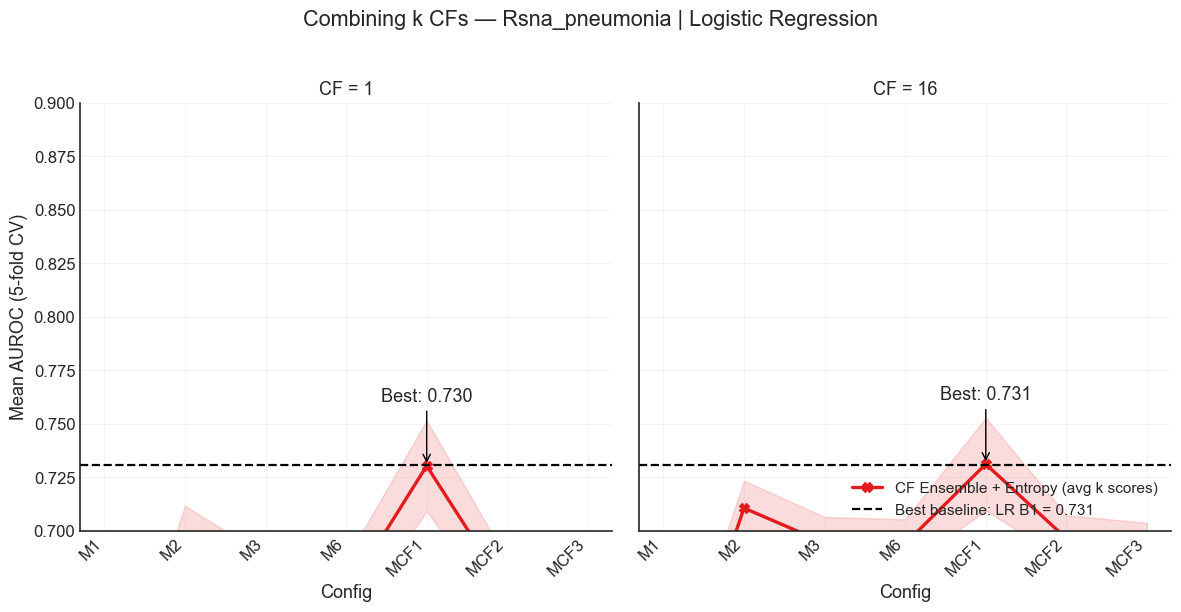

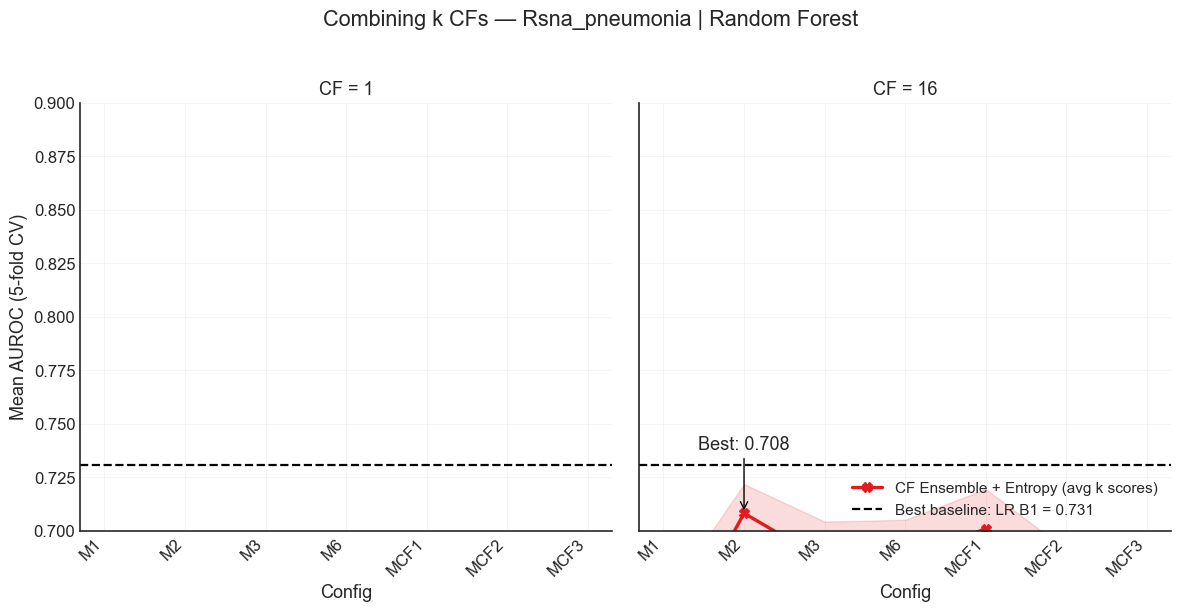

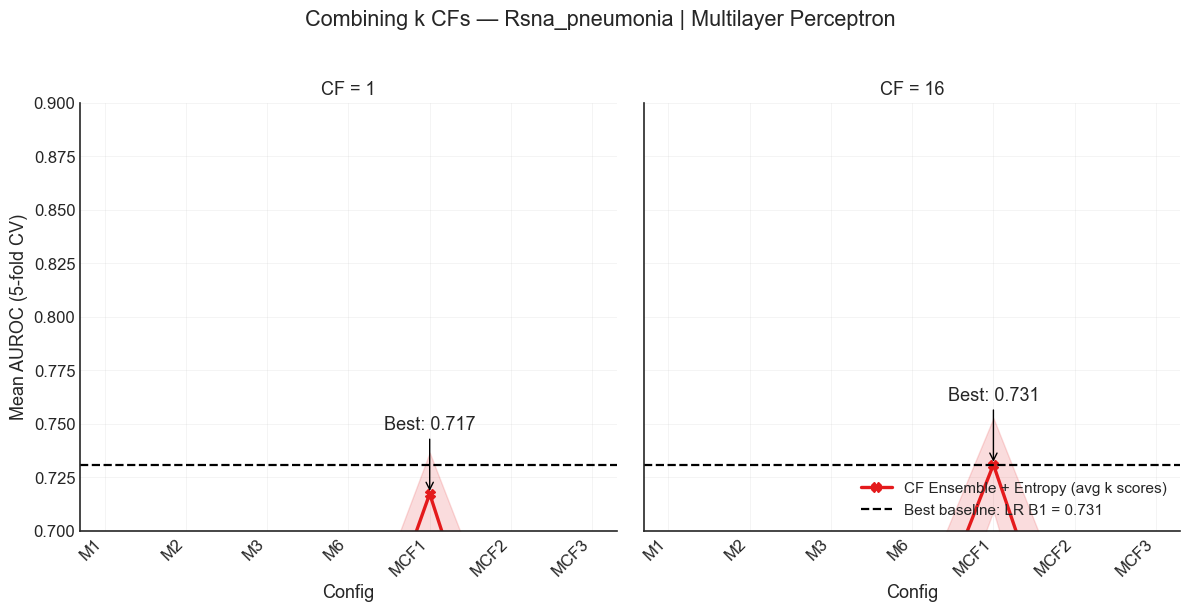

Mean AUC by strategy — CF=1, rsna_pneumonia


strategy      cf_ensemble_entropy
model config                     
LR    M1                   0.5834
      M2                   0.6973
      M3                   0.6711
      M6                   0.6703
      MCF1                 0.7304
      MCF2                 0.6717
      MCF3                 0.6654
MLP   M1                   0.5374
      M2                   0.5914
      M3                   0.6056
      M6                   0.6106
      MCF1                 0.7174
      MCF2                 0.6003
      MCF3                 0.5698
RF    M1                   0.5944
      M2                   0.6785
      M3                   0.6638
      M6                   0.6685
      MCF1                 0.6544
      MCF2                 0.6439
      MCF3                 0.6538

Mean AUC by strategy — CF=16, rsna_pneumonia


strategy      cf_ensemble_entropy
model config                     
LR    M1                   0.6009
      M2                   0.7107
      M3                   0.6945
      M6                   0.6941
      MCF1                 0.7312
      MCF2                 0.6965
      MCF3                 0.6923
MLP   M1                   0.5556
      M2                   0.6280
      M3                   0.6249
      M6                   0.6343
      MCF1                 0.7310
      MCF2                 0.6196
      MCF3                 0.5769
RF    M1                   0.6388
      M2                   0.7083
      M3                   0.6863
      M6                   0.6858
      MCF1                 0.7012
      MCF2                 0.6752
      MCF3                 0.6796

In [ ]:
# ── Combining k CFs: pick strategies, plot them ───────────────────────────────
# Ways to turn k counterfactuals into one score:
#   correct_cf          — k nearest correct-CFs collapsed into ONE feature row
#                         (ΔA averaged over the k); a single classifier scores it.
#   cf_ensemble         — train on the nearest CF only; at test time score each
#                         of the k CFs and AVERAGE the k probabilities.
#   cf_stack            — same base model as cf_ensemble, but the k logits are
#                         combined by a learned meta-LR instead of a plain mean.
#   cf_ensemble_entropy — cf_ensemble with entropy-for-prob + high-capacity MLP.
# Add/remove keys below; anything without a run on disk is skipped with a warning.
ENS_STRATEGIES = ['cf_ensemble_entropy']
ENS_CF_COUNTS  = [1,16]

# Long frame: one row per (strategy, cf_count, model, config) — no merge chain.
ens_df = pd.concat(
    [f for s in ENS_STRATEGIES for cf in ENS_CF_COUNTS
     if (f := load_summary(s, cf)) is not None],
    ignore_index=True)

for s in ENS_STRATEGIES:
    for cf in ENS_CF_COUNTS:
        if not has_run(s, cf):
            print(f'⚠ No run: {STRATEGIES[s][2]} at CF={cf} — skipped')

ens_df.to_csv(os.path.join(OUTPUT_DIR, f'cf_ensemble_vs_correct_cf_{DISEASE}.csv'),
              index=False)

# Best baseline: all B* configs, all models, across the selected strategies.
BASELINE_CONFIGS = ['B1']
_base = ens_df[ens_df['config'].isin(BASELINE_CONFIGS)]
BEST_BASELINE = _base.loc[_base['mean_auc'].idxmax()]
print(f"Loaded {ens_df['strategy'].nunique()} strategies | best baseline: "
      f"{STRATEGIES[BEST_BASELINE['strategy']][2]} {BEST_BASELINE['model']} "
      f"{BEST_BASELINE['config']} = {BEST_BASELINE['mean_auc']:.3f}")


# ── Plot: one line per strategy, x = CF-dependent config ──────────────────────
def plot_ensemble_vs_correct(model):
    sub = ens_df[ens_df['model'] == model]
    if sub.empty:
        print(f'⚠ No data for {model}')
        return

    fig, axes = plt.subplots(1, len(ENS_CF_COUNTS), figsize=(6 * len(ENS_CF_COUNTS), 6),
                             sharey=True, squeeze=False)
    for ax, cf in zip(axes[0], ENS_CF_COUNTS):
        at_cf = sub[sub['cf_count'] == cf]
        present = [c for c in CF_CONFIGS if c in at_cf['config'].values]
        if not present:
            ax.set_visible(False)
            continue
        x = np.arange(len(present))

        for strategy in ENS_STRATEGIES:
            s = at_cf[at_cf['strategy'] == strategy].set_index('config')
            s = s.reindex(present)               # NaN → gap, config absent for this run
            if s['mean_auc'].isna().all():
                continue
            ax.plot(x, s['mean_auc'].values, color=STRATEGY_COLORS[strategy],
                    lw=2.4, marker=STRATEGY_MARKERS[strategy], ms=7,
                    label=STRATEGIES[strategy][2])
            ax.fill_between(x, s['mean_auc'] - s['std_auc'], s['mean_auc'] + s['std_auc'],
                            color=STRATEGY_COLORS[strategy], alpha=0.15)

            # Restrict to rows that are actually visible in this subplot
            plotted = at_cf[at_cf['config'].isin(present)]

            if not plotted.empty:
                best_row = plotted.loc[plotted['mean_auc'].idxmax()]  # row with highest mean_auc
                best_x = present.index(best_row['config'])             # x-position on the categorical axis
                best_y = best_row['mean_auc']

                ax.annotate(
                    f"Best: {best_y:.3f}",
                    xy=(best_x, best_y),                # the point being annotated
                    xytext=(best_x, best_y + 0.03),     # where the text box sits
                    ha='center', fontsize=13,
                    arrowprops=dict(arrowstyle='->', color='black', lw=1)
    )
    
        ax.axhline(BEST_BASELINE['mean_auc'], color='black', linestyle='--', lw=1.6,
                   label=(f"Best baseline: "
                          f"{BEST_BASELINE['model']} {BEST_BASELINE['config']} "
                          f"= {BEST_BASELINE['mean_auc']:.3f}"))

        ax.set_ylim(min(0.65, at_cf['mean_auc'].min() - 0.02), 0.80)
        ax.set_xticks(x); ax.set_xticklabels(present, rotation=45, ha='right')
        ax.set_title(f'CF = {cf}'); ax.set_xlabel('Config')
        ax.grid(alpha=0.3, linewidth=0.5)

    axes[0][0].set_ylabel('Mean AUROC (5-fold CV)')
    axes[0][-1].legend(loc='lower right', framealpha=0.9, edgecolor='#cccccc')
    fig.suptitle(f'Combining k CFs — {DISEASE.capitalize()} | {MODEL_NAMES[model]}', y=1.02)
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, f'cf_ensemble_vs_correct_cf_{model}_{DISEASE}.png'),
                dpi=300, bbox_inches='tight')
    plt.ylim(0.7, 0.90)
    plt.show()

for model in MODELS:
    plot_ensemble_vs_correct(model)


# ── Table: strategy × config AUC, per CF count ────────────────────────────────
for cf in ENS_CF_COUNTS:
    s = ens_df[(ens_df['cf_count'] == cf) & ens_df['config'].isin(CF_CONFIGS)]
    if s.empty:
        continue
    print(f'Mean AUC by strategy — CF={cf}, {DISEASE}')
    display(s.pivot_table(index=['model', 'config'], columns='strategy',
                          values='mean_auc')
             .reindex(columns=[x for x in ENS_STRATEGIES if x in s['strategy'].values])
             .round(4))

## C0 confidence stratification 


In [ ]:
def pooled_banded_msp(strategy, cf):
    """Same as pooled_banded(), but for the untrained MSP score (no model, no config)."""
    det = load_detailed(strategy, cf)['MLP']['B1']   # only used to get y_true / fold structure
    d   = run_dir(strategy, cf)
    y, c0 = [], []
    for i, f in enumerate(det):
        y.append(np.asarray(f['y_true'], float))
        c0.append(pd.read_csv(os.path.join(d, f'fold_{i}_predictions.csv'))
                  [f'{DISEASE}_prob'].values)
    y, c0 = np.concatenate(y), np.concatenate(c0)
    p_msp = np.maximum(c0, 1 - c0)   # MSP score

    out = {}
    for lo, hi in STRAT_BANDS:
        msk = (c0 >= lo) & (c0 < hi)
        yb, pb = y[msk], p_msp[msk]
        n = int(msk.sum())
        if n == 0 or yb.min() == yb.max():
            out[(lo, hi)] = (np.nan, np.nan, np.nan, n)
            continue
        auc = roc_auc_score(yb, pb)
        boots = []
        for _ in range(N_BOOT):
            idx = rng.integers(0, len(yb), len(yb))
            if yb[idx].min() == yb[idx].max():
                continue
            boots.append(roc_auc_score(yb[idx], pb[idx]))
        lo95, hi95 = (np.percentile(boots, [2.5, 97.5]) if boots else (np.nan, np.nan))
        out[(lo, hi)] = (auc, lo95, hi95, n)
    return out

In [10]:
# ── 8. C0 confidence stratification ──────────────────────────────────────────
# AUC within bands of the C0 probability. Confidence-based baselines (B1) are
# blind where prob ≈ 0.5; CF features should help exactly there.

# Read tau (threshold from results/C0_custom/<disease>/threshold.txt)
TAU = float(open(f"/zhome/d0/a/221493/thesis/results/C0_custom/{DISEASE}/threshold.txt").read().strip())
print(f'Loaded τ = {TAU:.3f} from threshold.txt')

# Bands centred on τ: the middle band straddles the boundary (±0.10),
# the two flanks are "uncertain" each side, the tails are confident predictions.
STRAT_BANDS = [
    (0.0,        TAU - 0.30),   # confident negative (pred 0, far)
    (TAU - 0.30, TAU - 0.10),   # uncertain negative
    (TAU - 0.10, TAU + 0.10),   # BOUNDARY (straddles τ)
    (TAU + 0.10, TAU + 0.30),   # uncertain positive
    (TAU + 0.30, 1.001),        # confident positive (pred 1, far)
]


N_BOOT = 1000
rng = np.random.default_rng(0)


def pooled_banded(strategy, cf, model, config):
    """Pool test folds; return per-band (auc, lo, hi, n) with bootstrap 95% CI.

    Bands can be empty or single-class → those return NaN instead of raising.
    """
    det = load_detailed(strategy, cf)[model][config]
    d   = run_dir(strategy, cf)
    y, p, c0 = [], [], []
    for i, f in enumerate(det):
        y.append(np.asarray(f['y_true'], float))
        p.append(np.asarray(f['y_prob'], float))
        c0.append(pd.read_csv(os.path.join(d, f'fold_{i}_predictions.csv'))
                  [f'{DISEASE}_prob'].values)
    y, p, c0 = np.concatenate(y), np.concatenate(p), np.concatenate(c0)

    out = {}
    for lo, hi in STRAT_BANDS:
        msk = (c0 >= lo) & (c0 < hi)
        yb, pb = y[msk], p[msk]
        n = int(msk.sum())
        if n == 0 or yb.min() == yb.max():
            out[(lo, hi)] = (np.nan, np.nan, np.nan, n)
            continue
        auc = roc_auc_score(yb, pb)
        boots = []
        for _ in range(N_BOOT):
            idx = rng.integers(0, len(yb), len(yb))
            if yb[idx].min() == yb[idx].max():
                continue
            boots.append(roc_auc_score(yb[idx], pb[idx]))
        lo95, hi95 = (np.percentile(boots, [2.5, 97.5]) if boots else (np.nan, np.nan))
        out[(lo, hi)] = (auc, lo95, hi95, n)
    return out



Loaded τ = 0.452 from threshold.txt


In [12]:
# ── overlay: per-band counts, split by C0 correctness (log right-axis) ───────
det0, d0 = load_detailed('cf_ensemble_entropy', 16)['MLP']['B1'], run_dir('cf_ensemble_entropy', 1)
yc, c0d = [], []
for i, f in enumerate(det0):
    yc.append(f['y_true'])                                   # 1 = C0 correct
    c0d.append(pd.read_csv(os.path.join(d0, f'fold_{i}_predictions.csv'))
               [f'{DISEASE}_prob'].values)
yc  = np.concatenate(np.array(yc, object)).astype(int)
c0d = np.concatenate(c0d)

n_corr = [int(((c0d >= lo) & (c0d < hi) & (yc == 1)).sum()) for lo, hi in STRAT_BANDS]
n_err  = [int(((c0d >= lo) & (c0d < hi) & (yc == 0)).sum()) for lo, hi in STRAT_BANDS]



FileNotFoundError: [Errno 2] No such file or directory: '/zhome/d0/a/221493/thesis/results/C2_custom_corrected/rsna_pneumonia/cv_results_cf_ensemble/cf_16/distance_l1/strategy_correct_cf/TEST_entropy_added(M-only)/cv_detailed.json'

In [ ]:
# ── Which curves to stratify ─────────────────────────────────────────────────
# MSP = untrained max-softmax baseline (no model, no CFs).
# MCF5/RF is the best CF config on RSNA at k=16 (0.7287 vs 0.7204 for B1/MLP).
strat = {
    'MSP (Hendrycks & Gimpel, 2017)': pooled_banded_msp('cf_ensemble_entropy', 16),
    'MCF5 RF (Ensemble, K=16 CCF)':   pooled_banded('cf_ensemble_entropy', 16, 'RF', 'MCF5'),
}


In [ ]:
# ── per-band error decomposition: C0's FN / FP ───────────────────────────────
# Bands are defined on C0's prob and pred = (prob > TAU), so every band below TAU
# contains only false negatives and every band above it only false positives;
# the boundary band is the one that mixes both.
_e = pd.concat([pd.read_csv(os.path.join(run_dir('cf_ensemble_entropy', 16),
                                         f'fold_{i}_predictions.csv'),
                            usecols=[f'{DISEASE}_prob', f'{DISEASE}_pred', f'{DISEASE}_true'])
                for i in range(5)], ignore_index=True)
_p = _e[f'{DISEASE}_prob'].values
band_fn = [int(((_e[f'{DISEASE}_pred'] == 0) & (_e[f'{DISEASE}_true'] == 1) &
                (_p >= lo) & (_p < hi)).sum()) for lo, hi in STRAT_BANDS]
band_fp = [int(((_e[f'{DISEASE}_pred'] == 1) & (_e[f'{DISEASE}_true'] == 0) &
                (_p >= lo) & (_p < hi)).sum()) for lo, hi in STRAT_BANDS]
print('FN per band:', band_fn, '\nFP per band:', band_fp)


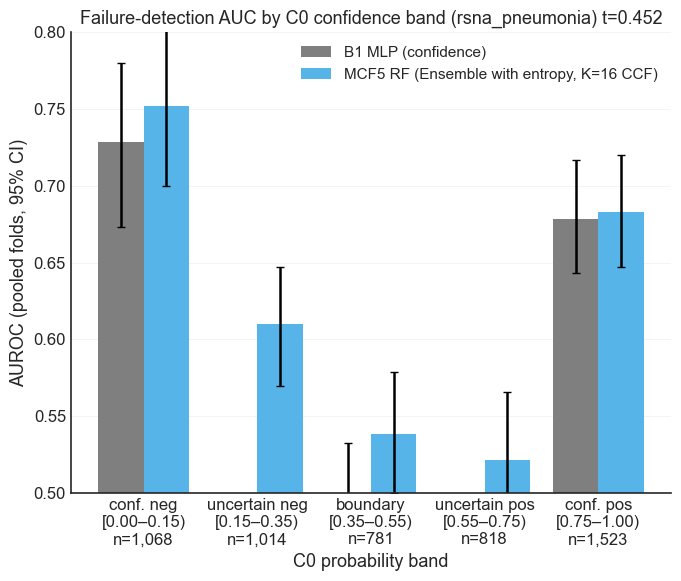

In [ ]:


# ── Plot: AUC per C0-confidence band ──────────────────────────────────────────
fig, ax = plt.subplots(figsize=(7, 6))

TAGS = ['conf. neg', 'uncertain neg', 'boundary', 'uncertain pos', 'conf. pos']
BAND_LABELS = [f'{tag}\n[{lo:.2f}–{min(hi, 1.0):.2f})'
               for tag, (lo, hi) in zip(TAGS, STRAT_BANDS)]

width = 0.8 / len(strat)
xs = np.arange(len(STRAT_BANDS))
for j, (label, res) in enumerate(strat.items()):
    aucs = [res[b][0] for b in STRAT_BANDS]
    err  = np.array([[res[b][0] - res[b][1] for b in STRAT_BANDS],
                     [res[b][2] - res[b][0] for b in STRAT_BANDS]])
    color = ('#7F7F7F' if label.startswith('B1')
             else list(STRATEGY_COLORS.values())[j])
    ax.bar(xs + j * width, aucs, width, yerr=err, capsize=3,
           color=color, label=label)
    
# ── overlay: % correct / incorrect per band (right axis, 0–100%) ─────────────
pct_corr, pct_err = [], []
for lo, hi in STRAT_BANDS:
    m = (c0d >= lo) & (c0d < hi)
    pct_corr.append(100 * (yc[m] == 1).sum() / m.sum())
    pct_err.append( 100 * (yc[m] == 0).sum() / m.sum())



ax.axhline(0.5, color='black', ls=':', lw=0.8, alpha=0.6)
ns = [next(iter(strat.values()))[b][3] for b in STRAT_BANDS]
ax.set_xticks(xs + width * (len(strat) - 1) / 2)
ax.set_xticklabels([f'{lab}\nn={n:,}  FN={fn} FP={fp}'
                    for lab, n, fn, fp in zip(BAND_LABELS, ns, band_fn, band_fp)],
                   fontsize=8)
ax.set_xlabel('C0 probability band'); ax.set_ylabel('AUROC (pooled folds, 95% CI)')
ax.set_ylim(0.5, 0.8)
ax.set_title(f'Failure-detection AUC by C0 confidence band ({DISEASE}) t={TAU:.3f}')
ax.legend(loc='upper right', framealpha=0.9, edgecolor='#cccccc')
ax.grid(alpha=0.3, linewidth=0.5, axis='y')
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, f'confidence_stratified_auc_{DISEASE}.png'),
            dpi=300, bbox_inches='tight')
plt.show()


## 11. Appendix — Other Result Trees

These experiments live outside `C2_custom_corrected`:
**11a** C2 across backbone architectures and diseases (`C2_custom` / `C2_resnet50` / `C2_vit`);
**11b** dataset-size ablation (`C2_custom`, effusion-only sub-sampled runs).

*Note: 10a fixes a bug in the previous notebook version, which plotted the effusion
results for all three diseases.*

⚠ missing: /zhome/d0/a/221493/thesis/results/C2_custom/effusion/cv_results/cf_16/cv_summary.csv
⚠ missing: /zhome/d0/a/221493/thesis/results/C2_custom/cardiomegaly/cv_results/cf_16/cv_summary.csv
⚠ missing: /zhome/d0/a/221493/thesis/results/C2_custom/pneumothorax/cv_results/cf_16/cv_summary.csv


/work3/s251710/thesis_env_new/lib64/python3.9/site-packages/matplotlib/axes/_axes.py:1185: RuntimeWarning: All-NaN axis encountered
  miny = np.nanmin(masked_verts[..., 1])
/work3/s251710/thesis_env_new/lib64/python3.9/site-packages/matplotlib/axes/_axes.py:1186: RuntimeWarning: All-NaN axis encountered
  maxy = np.nanmax(masked_verts[..., 1])


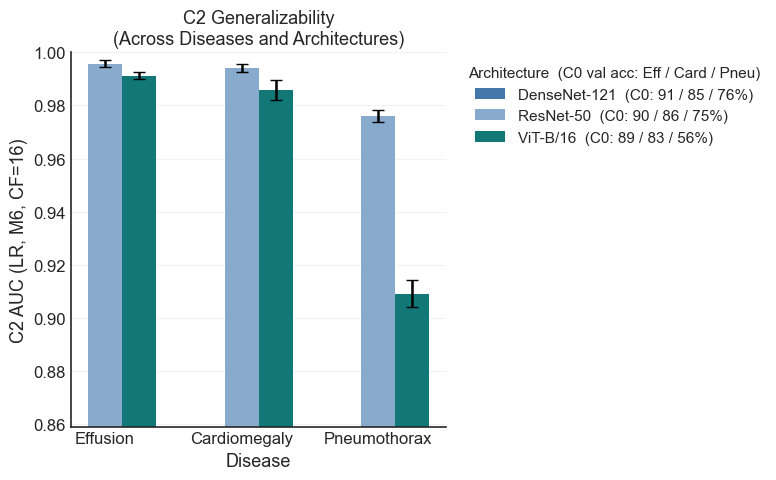

,Effusion,Cardiomegaly,Pneumothorax
DenseNet-121,NaN,NaN,NaN
ResNet-50,0.9957,0.9941,0.9758
ViT-B/16,0.9911,0.9858,0.9092


In [19]:
# ── 11a. C2 AUC across architectures × diseases ───────────────────────────────
ARCH_TREES = {
    'DenseNet-121': f'{BASE_DIR}/results/C2_custom',
    'ResNet-50':    f'{BASE_DIR}/results/C2_resnet50',
    'ViT-B/16':     f'{BASE_DIR}/results/C2_vit',
}
ARCH_COLORS  = {'DenseNet-121': '#4477AA', 'ResNet-50': '#88AACC', 'ViT-B/16': '#117777'}
GEN_DISEASES = ['effusion', 'cardiomegaly', 'pneumothorax']
GEN_MODEL, GEN_CONFIG, GEN_CF = 'LR', 'M6', 16

# C0 validation accuracy (%) per disease (Eff / Card / Pneu), from the C0 runs
C0_ACC = {
    'DenseNet-121': [91.1, 85.2, 75.9],
    'ResNet-50':    [90.5, 85.9, 75.3],
    'ViT-B/16':     [88.8, 82.7, 56.3],
}

gen_auc = np.full((len(ARCH_TREES), len(GEN_DISEASES)), np.nan)
gen_std = np.full_like(gen_auc, np.nan)
for i, tree in enumerate(ARCH_TREES.values()):
    for j, dis in enumerate(GEN_DISEASES):
        path = f'{tree}/{dis}/cv_results/cf_{GEN_CF}/cv_summary.csv'
        if not os.path.exists(path):
            print(f'⚠ missing: {path}')
            continue
        s = pd.read_csv(path)
        row = s[(s['model'] == GEN_MODEL) & (s['config'] == GEN_CONFIG)]
        if row.empty:
            print(f'⚠ {GEN_MODEL}/{GEN_CONFIG} not in {path}')
            continue
        gen_auc[i, j] = row['mean_auc'].iloc[0]
        gen_std[i, j] = row['std_auc'].iloc[0]

x, width = np.arange(len(GEN_DISEASES)), 0.25
fig, ax = plt.subplots(figsize=(8, 5))
for i, (arch, color) in enumerate(ARCH_COLORS.items()):
    c0_str = ' / '.join(f'{v:.0f}' for v in C0_ACC[arch])
    ax.bar(x + (i - 1) * width, gen_auc[i], width, yerr=gen_std[i], capsize=4,
           color=color, linewidth=1.2, label=f'{arch}  (C0: {c0_str}%)')
ax.set_xticks(x); ax.set_xticklabels([d.capitalize() for d in GEN_DISEASES])
ax.set_ylabel(f'C2 AUC ({GEN_MODEL}, {GEN_CONFIG}, CF={GEN_CF})')
ax.set_xlabel('Disease')
ax.set_ylim(max(0.0, np.nanmin(gen_auc) - 0.05), 1.0)
ax.set_title('C2 Generalizability\n(Across Diseases and Architectures)')
ax.grid(axis='y', alpha=0.3)
ax.legend(title='Architecture  (C0 val acc: Eff / Card / Pneu)',
          bbox_to_anchor=(1.02, 1), fontsize=11, title_fontsize=11)

_out = f'{BASE_DIR}/results/C2_generalizability'
os.makedirs(_out, exist_ok=True)
plt.savefig(os.path.join(_out, 'c2_generalizability_across_diseases.png'),
            dpi=300, bbox_inches='tight')
plt.tight_layout()
plt.show()

display(pd.DataFrame(gen_auc, index=list(ARCH_TREES),
                     columns=[d.capitalize() for d in GEN_DISEASES]).round(4))

⚠ missing: /zhome/d0/a/221493/thesis/results/C2_custom/effusion/cv_results/cf_16/cv_summary.csv
⚠ missing: /zhome/d0/a/221493/thesis/results/C2_custom/effusion/cv_results/cf_16_sub30000/cv_summary.csv
⚠ missing: /zhome/d0/a/221493/thesis/results/C2_custom/effusion/cv_results/cf_16_sub20000/cv_summary.csv
⚠ missing: /zhome/d0/a/221493/thesis/results/C2_custom/effusion/cv_results/cf_16_sub10000/cv_summary.csv
⚠ missing: /zhome/d0/a/221493/thesis/results/C2_custom/effusion/cv_results/cf_16_sub5000/cv_summary.csv


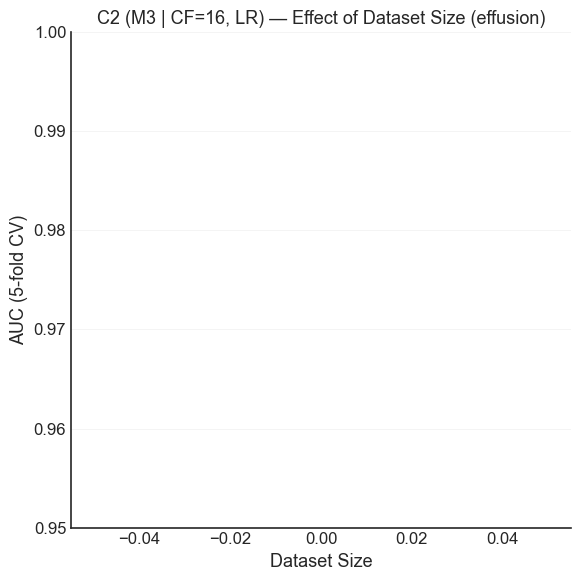

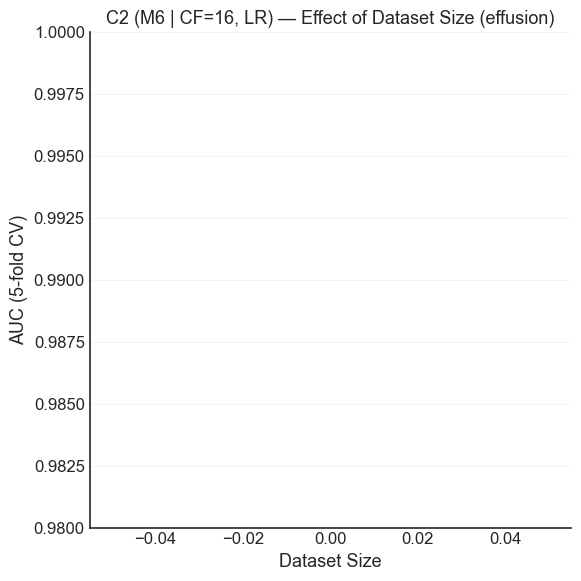

,Dataset Size,AUC,AUC Std


,Dataset Size,AUC,AUC Std


\begin{tabular}{rrr}
\toprule
Dataset Size & AUC & AUC Std \\
\midrule
\bottomrule
\end{tabular}



In [20]:
# ── 11b. Dataset-size ablation (C2_custom, effusion, CF=16) ───────────────────
SIZE_TREE = f'{BASE_DIR}/results/C2_custom/effusion/cv_results'
SIZE_RUNS = [('45k (Full)', f'{SIZE_TREE}/cf_16'),
             ('30k',        f'{SIZE_TREE}/cf_16_sub30000'),
             ('20k',        f'{SIZE_TREE}/cf_16_sub20000'),
             ('10k',        f'{SIZE_TREE}/cf_16_sub10000'),
             ('5k',         f'{SIZE_TREE}/cf_16_sub5000')]

size_summ = {}
for lbl, d in SIZE_RUNS:
    p = f'{d}/cv_summary.csv'
    if os.path.exists(p):
        size_summ[lbl] = pd.read_csv(p)
    else:
        print(f'⚠ missing: {p}')

def size_series(config, model='LR'):
    labels, aucs, stds = [], [], []
    for lbl, _ in SIZE_RUNS:
        if lbl not in size_summ:
            continue
        s = size_summ[lbl]
        row = s[(s['model'] == model) & (s['config'] == config)]
        if row.empty:
            print(f'{config}: not in {lbl} run — omitted.')
            continue
        labels.append(lbl)
        aucs.append(row['mean_auc'].iloc[0])
        stds.append(row['std_auc'].iloc[0])
    return labels, aucs, stds

def plot_size_effect(config, highlight, rest, ylim, model='LR'):
    labels, aucs, stds = size_series(config, model)
    plt.figure(figsize=(6, 6))
    plt.bar(labels, aucs, yerr=stds, capsize=10,
            color=[highlight] + [rest] * (len(labels) - 1), linewidth=1.2)
    plt.ylabel('AUC (5-fold CV)'); plt.xlabel('Dataset Size')
    plt.title(f'C2 ({config} | CF=16, {model}) — Effect of Dataset Size (effusion)',
              fontsize=13)
    plt.ylim(*ylim)
    plt.grid(axis='y', alpha=0.3, linewidth=0.5)
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, f'dataset_size_{config}_{model}_effusion.png'),
                dpi=150, bbox_inches='tight')
    plt.show()
    return pd.DataFrame({'Dataset Size': labels, 'AUC': aucs, 'AUC Std': stds})

df_m3 = plot_size_effect('M3', '#117777', '#88AACC', ylim=(0.95, 1))
df_m6 = plot_size_effect('M6', '#D04B4B', '#839BB3', ylim=(0.98, 1))
display(df_m3.round(4)); display(df_m6.round(4))
print(df_m6.to_latex(index=False, float_format='%.4f'))